# MATPLOTLIB MASTERY — NOTEBOOK 1
## Chapters 1–5: Foundations → Object-Oriented Model → First Plot → Line Plots → Labels & Titles

**Prerequisite assumption:** You already know Python, NumPy, and Pandas at a working level. This notebook does **not** re-teach those — it builds visualization skill directly on top of them, aimed at production-grade Data Science / ML work.

### Progress Tracker (this notebook)
- [x] Chapter 1 — Matplotlib Foundation
- [x] Chapter 2 — Figure / Axes / Axis Architecture (Object-Oriented Model)
- [x] Chapter 3 — First Professional Plot
- [x] Chapter 4 — Line Plots
- [x] Chapter 5 — Labels and Titles

Everything below is meant to be **run cell by cell** in Jupyter. Read the theory, run the code, then attempt the exercises before checking the answers further down.


---
# CHAPTER 1 — MATPLOTLIB FOUNDATION

## 1. Concept

```
NumPy  →  Numerical Data
   ↓
Pandas →  Structured Data
   ↓
Matplotlib → Visualization
   ↓
Human Understanding → Decisions
```

Matplotlib is a **plotting library**, but more precisely it is a **drawing engine that turns arrays of numbers into pixels/vectors on a canvas**. It was created in the early 2000s (John Hunter) to give Python a MATLAB-style plotting workflow, but it evolved into something more powerful: a fully object-oriented graphics API where every visual element (a line, a tick mark, a piece of text) is an **Artist** object that knows how to draw itself.

Two APIs coexist:
- **pyplot (`plt`)** — a stateful, MATLAB-like convenience layer. Great for quick, throwaway plots.
- **Object-Oriented (OO) API (`fig`, `ax`)** — explicit objects you control directly. This is what production code, libraries, and complex figures use.

## 2. Why It Matters (professionally)

A table of numbers hides structure that the human visual system detects almost instantly: trend, seasonality, clusters, outliers, skew, non-linearity. In ML specifically, visualization is not decoration — it's a **diagnostic instrument**:
- You cannot detect overfitting from a single accuracy number as reliably as from a learning curve.
- You cannot understand *why* a regression model fails without a residual plot.
- You cannot explain a model to a non-technical stakeholder with a confusion matrix table as effectively as with a plotted one.

Numerical summaries (mean, std, correlation) can be **identical** for wildly different underlying data — this is the core lesson of **Anscombe's Quartet** and the more dramatic **Datasaurus Dozen**: several datasets with nearly identical summary statistics but completely different shapes when plotted. This is the single strongest argument for "always look at the data."

## 3. Connection to NumPy

Matplotlib's core plotting functions expect **array-like** input — Python lists, NumPy arrays, or anything that can be coerced into one via `np.asarray()`. Internally, when you call `ax.plot(x, y)`, Matplotlib converts `x` and `y` to NumPy arrays before computing data limits, transforms, and vertex paths. This means every trick you know from NumPy (broadcasting, vectorized math, boolean masking) works directly as plot input:

```python
mask = y > 0
ax.plot(x[mask], y[mask])   # plot only positive values
```

## 4. Connection to Pandas

A `pandas.Series` or `DataFrame` column is backed by a NumPy array (`.values` / `.to_numpy()`), so Matplotlib can consume it directly — `ax.plot(df["date"], df["sales"])` works because Matplotlib calls `np.asarray()` on each argument internally. Pandas also ships its own `.plot()` accessor, which is a thin convenience wrapper *around* Matplotlib (covered fully in Chapter 39) — it's still Matplotlib under the hood, just with sensible EDA defaults.

## 5. Industry Use Case

- **EDA in a Jupyter notebook** before any modeling starts.
- **Model evaluation reports** (ROC curves, confusion matrices) shipped in ML pipelines.
- **Dashboards and BI reports** rendered as static images (e.g., emailed PDF reports).
- **Scientific publications** — Matplotlib is the de facto standard for publication-quality static figures in Python.
- **Monitoring/observability** for production ML (data drift plots).

## 6. Import Convention

```python
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
```

- `matplotlib` — the top-level package (rarely imported directly).
- `pyplot` — the submodule providing the plotting interface (stateful convenience functions **and** the entry point for creating Figure/Axes objects).
- `as plt` — universal community convention; not required, but expected in every codebase, tutorial, and Stack Overflow answer you will ever read. Consistency here is a readability best practice, not a technical requirement.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("Matplotlib version:", matplotlib.__version__)
print("Default backend:", matplotlib.get_backend())


Matplotlib version: 3.10.0
Default backend: module://matplotlib_inline.backend_inline


### Internal Working (conceptual, Chapter 1 level)

When Python executes `import matplotlib.pyplot as plt`, Matplotlib:
1. Loads its configuration (`rcParams`) from a `matplotlibrc` file or built-in defaults.
2. Selects a **backend** — the rendering engine appropriate for your environment (inline images in Jupyter, an interactive window in a script, etc. — full detail in Chapter 84).
3. Initializes `pyplot`'s internal state machine, which keeps track of a "current figure" and "current axes" so that top-level calls like `plt.plot()` know where to draw.

### Common Mistakes (Chapter 1)
- Forgetting `import numpy as np` and then trying to use `np.linspace` → `NameError`.
- Mixing up `matplotlib.pyplot` (has `.plot()`) with `matplotlib` itself (does not).
- Assuming Matplotlib "shows" a plot automatically in a `.py` script without calling `plt.show()` (Jupyter auto-displays the last figure in a cell; scripts do not).

### Interview Insight
**Q: What is Matplotlib, in one sentence, from an engineering perspective?**
A: It's a 2D (and basic 3D) plotting library that renders arrays of numeric data into vector or raster graphics via a layered object model (Figure → Axes → Artists), exposing both a stateful convenience API (`pyplot`) and an explicit object-oriented API.

### Mini Exercise
1. Print `plt.__name__` and confirm it equals `matplotlib.pyplot`.
2. Look up (`print(matplotlib.matplotlib_fname())`) where your active `matplotlibrc` config file lives.

### Quiz (Chapter 1)
1. What problem does data visualization solve that a printed table cannot?
2. What are the two main Matplotlib APIs and when would you pick each?
3. Why can a NumPy array be passed directly into `ax.plot()`?


---
# CHAPTER 2 — MATPLOTLIB OBJECT-ORIENTED MODEL

## 1. Concept

Everything Matplotlib draws is organized into a strict containment hierarchy:

```
Figure
│   (the whole canvas / window / image file)
│
├── Axes            (a single "plot" — the region with data, one per subplot)
│   ├── XAxis       (the x-axis object: ticks, tick labels, axis label)
│   ├── YAxis       (the y-axis object)
│   ├── Lines       (Line2D artists — from ax.plot())
│   ├── Patches     (Rectangle, Circle, Wedge — bars, pie slices)
│   ├── Text        (titles, annotations, tick labels)
│   ├── Legend
│   └── Spines      (the box edges around the axes)
│
└── (More Axes if you have subplots)
```

**Crucial vocabulary distinction** (a classic interview trap):
- **Figure** = the entire image/canvas. One `savefig()` call saves one Figure.
- **Axes** = one individual plot (NOT the plural of "Axis"!). A Figure can contain many Axes (subplots).
- **Axis** = a single x- or y- axis *within* an Axes (controls ticks, limits, scale, label).

## 2. Why It Matters

`plt.plot()` (pyplot/state-based) implicitly creates a Figure and Axes for you and remembers them as "current." This is fine for one throwaway plot, but breaks down fast:
- You lose explicit references to reuse or modify axes later.
- It's dangerous inside **functions/loops** — global state can silently point at the wrong axes.
- It doesn't scale to **multiple subplots** cleanly.

Professional and production code almost always uses:
```python
fig, ax = plt.subplots()
ax.plot(...)
```
because `fig` and `ax` are **explicit local objects** — safe to pass around, test, and reuse, exactly like any other Python object.

## 3. Connection to NumPy / 4. Connection to Pandas

The hierarchy itself doesn't touch NumPy/Pandas directly — but every Artist under an Axes (a `Line2D`, a `Rectangle`) stores its geometry as NumPy arrays internally (`line.get_xdata()` returns a NumPy array). When you later need to inspect or debug what got drawn, you're inspecting NumPy arrays.

## 5. Industry Use Case

Any codebase with a `visualization.py` module (Chapter 87) is built entirely on the OO API, because functions need to accept/return `fig, ax` objects to be composable and testable.


In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

print("type(fig):", type(fig))
print("type(ax):", type(ax))
print("Is ax inside fig?", ax in fig.axes)
print("Number of axes in this figure:", len(fig.axes))
print()
print("XAxis object:", ax.xaxis)
print("YAxis object:", ax.yaxis)
print("Spines:", list(ax.spines.keys()))

plt.close(fig)  # close so it doesn't render an empty box here


type(fig): <class 'matplotlib.figure.Figure'>
type(ax): <class 'matplotlib.axes._axes.Axes'>
Is ax inside fig? True
Number of axes in this figure: 1

XAxis object: XAxis(75.0,43.99999999999999)
YAxis object: YAxis(75.0,43.99999999999999)
Spines: ['left', 'right', 'bottom', 'top']


### Line-by-Line Explanation
- `fig, ax = plt.subplots(figsize=(6, 4))` — creates **one** Figure and **one** Axes inside it, unpacked into two variables. `figsize` is in **inches** (width, height).
- `type(fig)` → `matplotlib.figure.Figure`; `type(ax)` → `matplotlib.axes._axes.Axes`.
- `ax in fig.axes` — every Axes keeps a back-reference; a Figure stores its Axes list in `fig.axes`.
- `ax.xaxis` / `ax.yaxis` — the Axis objects, distinct from the Axes itself. This is the #1 vocabulary confusion in interviews.
- `ax.spines` — a dict-like container (`{'top', 'bottom', 'left', 'right'}`) of the border lines; each is a `Spine` Artist you can hide or move (used heavily in Chapter 12 for minimalist design).
- `plt.close(fig)` — releases the figure from memory/pyplot's internal registry. **Best practice**: always close figures you create in a loop or in a script that generates many plots, or you leak memory.

### Internal Working
`plt.subplots()` internally: (1) creates a `Figure` via `plt.figure()`, (2) calls `fig.add_subplot()` once per requested cell in the grid, wiring each new `Axes` into `fig.axes`, and (3) returns `(fig, ax)` or `(fig, axes_array)` depending on `nrows`/`ncols`.

### Why Professional Code Prefers `fig, ax = plt.subplots()` over `plt.*`
| pyplot (`plt.plot()`) | Object-Oriented (`ax.plot()`) |
|---|---|
| Implicit "current axes" state | Explicit object reference |
| Risky inside functions/loops | Safe — no global state |
| Fine for a single quick plot | Required for subplots/dashboards |
| Hard to unit-test | Testable — assert on `ax` properties |

### Common Mistakes
- Calling `plt.title()` after creating axes with `fig, ax = plt.subplots()` — it *usually* still works (pyplot tracks "current axes"), but it's inconsistent style; use `ax.set_title()` instead.
- Confusing "Axes" (a plot) with "Axis" (one dimension of a plot) in speech and in interviews.
- Not closing figures (`plt.close()`) when generating many programmatically — causes `RuntimeWarning: More than 20 figures have been opened.`

### Interview Insight
**Q: What's the difference between `plt.plot()` and `ax.plot()`?**
A: `plt.plot()` is a stateful pyplot call that implicitly plots onto "whatever the current axes is," creating one if none exists. `ax.plot()` plots explicitly onto a specific `Axes` object you already hold a reference to. They produce identical visual output for a single plot, but `ax.plot()` is required for reliable behavior with multiple subplots, functions, and production code.

**Q: A Figure has 4 Axes. How do you get the number of Line2D objects in the 2nd Axes?**
A: `len(fig.axes[1].lines)`

### Mini Exercise
Create a Figure with `figsize=(8, 5)`. Confirm `fig.get_size_inches()` returns `[8. 5.]`. Print `ax.spines['top'].get_visible()`.

### Coding Challenge
Write a function `describe_axes(ax)` that prints: whether the axes has any lines, how many, the x-limits, and the y-limits — using only `ax.lines`, `ax.get_xlim()`, `ax.get_ylim()`.


In [ ]:
def describe_axes(ax):
    print(f"Number of Line2D objects: {len(ax.lines)}")
    print(f"X limits: {ax.get_xlim()}")
    print(f"Y limits: {ax.get_ylim()}")

fig, ax = plt.subplots()
ax.plot([1, 2, 3], [4, 5, 6])
describe_axes(ax)
plt.close(fig)


Number of Line2D objects: 1
X limits: (np.float64(0.9), np.float64(3.1))
Y limits: (np.float64(3.9), np.float64(6.1))


### Quiz (Chapter 2)
1. Which object would you call `.savefig()` on — Figure or Axes?
2. What does `fig.axes` return?
3. True or False: `ax.xaxis` and `ax.get_xlim()` refer to the same underlying data.
4. Why is `fig, ax = plt.subplots()` preferred in reusable functions?

### Chapter 2 Summary
- Figure = whole canvas. Axes = one plot. Axis = one dimension (x or y) of an Axes.
- The OO API gives you explicit, safe object references — the professional default.
- Every Artist (`Line2D`, `Text`, `Patch`) lives inside an Axes, which lives inside a Figure.


---
# CHAPTER 3 — FIRST PROFESSIONAL PLOT

## 1–5: Concept / Why / NumPy / Pandas / Industry
This chapter is a hands-on synthesis of Chapters 1–2: build one clean, correctly-labeled plot the way you'd actually write it in a real notebook, then inspect every object it produced. The industry pattern below (`fig, ax = plt.subplots()` → plot → label → `plt.show()`) is the skeleton for essentially every figure you will ever build professionally.

### Markdown Cell (as you'd write it in a real notebook)
> **Business/analytical question:** How does `sin(x)` behave over one full period? (Standing in for: "How does this KPI/metric behave over its natural range?")


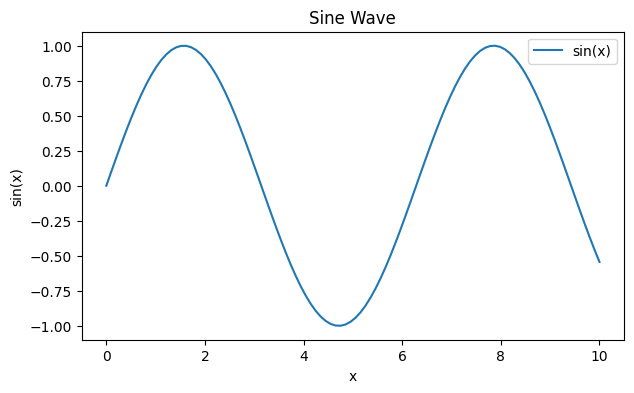

In [ ]:
x = np.linspace(0, 10, 100)   # 100 evenly spaced points from 0 to 10
y = np.sin(x)

fig, ax = plt.subplots(figsize=(7, 4))

line, = ax.plot(x, y, label="sin(x)")   # note the comma — plot() returns a LIST of Line2D

ax.set_title("Sine Wave")
ax.set_xlabel("x")
ax.set_ylabel("sin(x)")
ax.legend()

plt.show()


### Expected Output
A smooth sine curve oscillating between -1 and 1 across the x-range 0–10, with a title, axis labels, and a small legend box labeled "sin(x)".

### Line-by-Line Explanation
- `np.linspace(0, 10, 100)` — 100 evenly spaced samples; the *resolution* of your curve. Too few points → visibly jagged/faceted curve instead of smooth.
- `ax.plot(x, y, label="sin(x)")` — returns **a list** of `Line2D` objects (you can plot multiple lines in one call with paired x/y arguments, hence the list). `line, = ax.plot(...)` unpacks the single-element list — a common idiom you'll see everywhere.
- `label="sin(x)"` — does nothing visually by itself; it only registers the string for `ax.legend()` to pick up later.
- `ax.legend()` — scans all labeled artists in the Axes and draws a legend box.
- `plt.show()` — tells the backend to render/flush the figure. In Jupyter with the inline backend, the last figure in a cell auto-displays even without `plt.show()`, but calling it explicitly is still best practice (it also suppresses the `<matplotlib.legend.Legend at 0x...>` object-repr text output).

### Object Inspection


In [ ]:
print("type(fig):", type(fig))
print("type(ax):", type(ax))
print("type(line):", type(line))
print()
print("Line color (auto-assigned):", line.get_color())
print("Line xdata sample:", line.get_xdata()[:5])
print("Line ydata sample:", line.get_ydata()[:5])


type(fig): <class 'matplotlib.figure.Figure'>
type(ax): <class 'matplotlib.axes._axes.Axes'>
type(line): <class 'matplotlib.lines.Line2D'>

Line color (auto-assigned): #1f77b4
Line xdata sample: [0.        0.1010101 0.2020202 0.3030303 0.4040404]
Line ydata sample: [0.         0.10083842 0.20064886 0.2984138  0.39313661]


### Parameter Explanation
- `figsize=(7, 4)` — width × height in inches; combined with `dpi` (Chapter 30) determines final pixel dimensions.
- `label=` — only meaningful in combination with `.legend()`.

### Internal Working
`ax.plot(x, y)` converts `x`, `y` to NumPy arrays, computes a `Path` object connecting the vertices, wraps it in a `Line2D` Artist, appends that Artist to `ax.lines`, and updates the Axes' data limits (`ax.dataLim`) so that autoscaling (`ax.autoscale_view()`) knows how to set default x/y limits. Nothing is actually rendered to pixels until the backend's draw step runs (triggered by `plt.show()`, Jupyter's display hook, or `savefig()`).

### Interpretation
The curve should look smooth and periodic; if you compare it against the known period of sine (2π ≈ 6.28), you can visually verify the function completes roughly 1.6 cycles over the range 0–10 — this kind of "sanity check against known math" is exactly the instinct you'll later apply to verifying a model's predicted probabilities or a KPI's expected seasonality.

### Common Mistakes
- Forgetting the comma when unpacking: `line = ax.plot(x, y)` makes `line` a **list**, not a `Line2D` — then `line.get_color()` raises `AttributeError`.
- Using too few points in `linspace` for a smooth function (e.g., `np.linspace(0, 10, 5)`) → jagged, misleading curve.
- Calling `ax.legend()` when no artist has a `label` → produces an empty/warning-free but pointless legend, or (in recent Matplotlib) a `UserWarning: No artists with labels found`.

### Debugging
If `plt.show()` produces nothing in a `.py` script: confirm you're not using a non-interactive backend (`matplotlib.get_backend()`), and that the script isn't exiting before the GUI event loop runs.

### Best Practices
- Always create `fig, ax` explicitly.
- Always set title + axis labels — an unlabeled plot is not "done," professionally speaking.
- Prefer `ax.plot(..., label=...)` + `ax.legend()` over manual text placement whenever you have 2+ series.

### Interview Insight
**Q: What does `ax.plot()` return, and why does it return that type?**
A: A list of `Line2D` objects — a list because a single `plot()` call can draw multiple lines at once (e.g., `ax.plot(x, y1, x, y2)`), so the return type must accommodate that even when you only pass one series.

### Mini Exercise
Plot `y = np.cos(x)` on the same axes as `sin(x)` (add a second `ax.plot()` call before `ax.legend()`), and confirm two entries appear in the legend.

### Coding Challenge
Write a function `plot_function(func, x_range=(0, 10), n=200, ax=None)` that plots any NumPy-vectorized function (e.g., `np.tan`) over the given range, creating its own `fig, ax` if `ax` isn't passed, and returning `(fig, ax)`. This "accept an optional `ax`, return `fig, ax`" pattern is the standard signature for reusable plotting functions (formalized in Chapter 86).


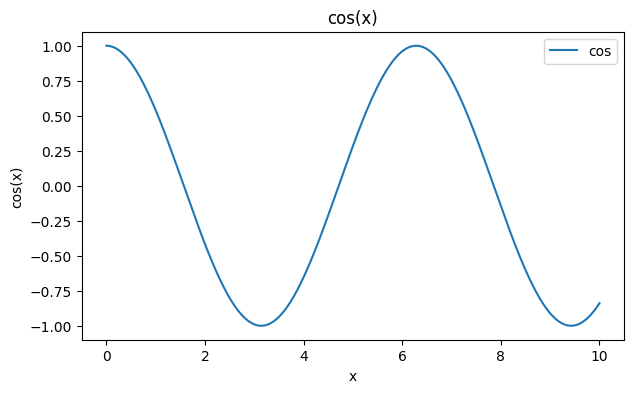

In [ ]:
def plot_function(func, x_range=(0, 10), n=200, ax=None):
    x = np.linspace(x_range[0], x_range[1], n)
    y = func(x)

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4))
    else:
        fig = ax.get_figure()

    ax.plot(x, y, label=func.__name__)
    ax.set_title(f"{func.__name__}(x)")
    ax.set_xlabel("x")
    ax.set_ylabel(f"{func.__name__}(x)")
    ax.legend()
    return fig, ax

fig, ax = plot_function(np.cos, x_range=(0, 10))
plt.show()


### Quiz (Chapter 3)
1. Why does `ax.plot()` return a list even for a single line?
2. What updates `ax.dataLim`, and why does that matter for autoscaling?
3. What's the risk of using very few points with `np.linspace` for a smooth mathematical function?

### Chapter 3 Summary
- The canonical professional pattern: `fig, ax = plt.subplots()` → `ax.plot(..., label=...)` → `ax.set_title/xlabel/ylabel()` → `ax.legend()` → `plt.show()`.
- `Line2D` objects are inspectable — `.get_xdata()`, `.get_ydata()`, `.get_color()` — useful for debugging and for automated testing of plotting functions.


---
# CHAPTER 4 — LINE PLOTS (Deep Dive)

## 1. Concept
`ax.plot()` draws connected line segments (and optionally markers) between (x, y) coordinate pairs. It is the right tool whenever **order along x is meaningful** — time, an increasing index, a sorted continuous variable — because Matplotlib draws segments strictly in the order the data is given.

## 2. Why It Matters
Line plots are the backbone of:
- **Time series** (revenue, users, sensor readings over time)
- **ML training curves** (loss/accuracy per epoch)
- **Continuous function visualization** (any mathematical relationship)

Misusing a line plot on **unordered categorical data** creates a misleading zig-zag that implies a trend or interpolation that doesn't exist — a classic chart-selection mistake (formalized in Chapter 80).

## 3–4. NumPy / Pandas Connection
`ax.plot()` accepts NumPy arrays directly, and Pandas Series/columns work identically because they expose the same array interface. A key production nuance: if a Pandas Series has a **non-default index** (e.g., after filtering), `ax.plot(series.index, series.values)` is more explicit and safer than `ax.plot(series)`, though both usually work.

## 5. Industry Use Case
- Model accuracy/loss per epoch (training vs validation).
- Daily/weekly revenue trend.
- Server latency over time.
- Any "metric vs continuous axis" relationship.

## Full Parameter Reference


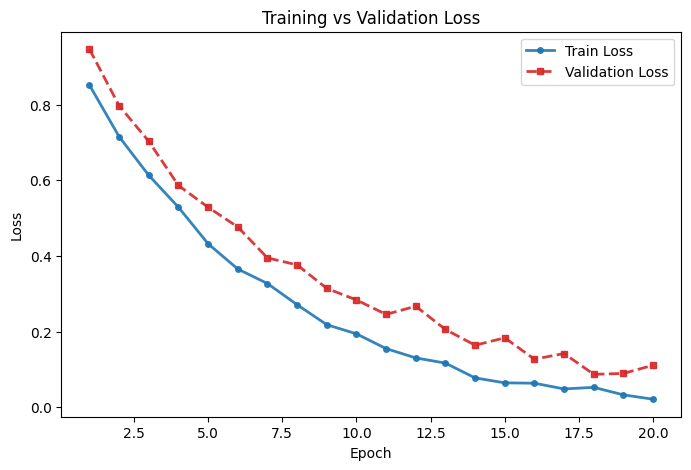

In [ ]:
np.random.seed(42)
epochs = np.arange(1, 21)
train_loss = np.exp(-epochs / 6) + np.random.normal(0, 0.01, size=20)
val_loss = np.exp(-epochs / 7) + 0.05 + np.random.normal(0, 0.02, size=20)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    epochs, train_loss,
    color="#1f77b4",       # explicit hex color (Chapter 7 goes deep on color)
    linewidth=2,
    linestyle="-",
    marker="o",
    markersize=4,
    alpha=0.9,
    label="Train Loss",
    zorder=2,              # draw order: higher = on top
)

ax.plot(
    epochs, val_loss,
    color="#d62728",
    linewidth=2,
    linestyle="--",
    marker="s",
    markersize=4,
    alpha=0.9,
    label="Validation Loss",
    zorder=2,
)

ax.set_title("Training vs Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
plt.show()


### Parameter Explanation
| Parameter | What it does | Default | Notes |
|---|---|---|---|
| `color` | Line color | auto-cycled | Named string, hex, or RGB(A) tuple |
| `linewidth` (`lw`) | Line thickness in points | `1.5` | Thicker for emphasis; thin for many overlapping series |
| `linestyle` (`ls`) | `-` solid, `--` dashed, `:` dotted, `-.` dash-dot | `-` | Use to distinguish series in grayscale/print |
| `marker` | Symbol at each data point (`o`, `s`, `^`, `x`, ...) | `None` | Adds clutter on dense data — use sparingly |
| `markersize` (`ms`) | Marker size in points | `6` | |
| `markeredgecolor` / `markerfacecolor` | Marker border/fill color | = line color | Useful for hollow markers |
| `alpha` | Transparency, 0 (invisible) – 1 (opaque) | `1` | Essential for overlapping/dense data |
| `label` | Legend text | `None` | Only matters with `ax.legend()` |
| `drawstyle` | `default`, `steps`, `steps-pre/mid/post` | `default` | `steps` for discrete/step-function data |
| `zorder` | Stacking order (higher drawn on top) | by call order | Rarely needed except with shaded regions |

### Internal Working
Each `ax.plot()` call with these style kwargs constructs one `Line2D` Artist whose drawing properties are simply attributes (`line.set_linewidth(2)` is equivalent to passing `linewidth=2` at creation time — everything is mutable after the fact too).

### Interpretation
Train loss dropping steadily below validation loss with a widening gap is the classic visual signature of **overfitting** — a pattern you would struggle to notice from a table of 20 numbers but is immediate in the plot.

### Common Mistakes
- Using near-identical default colors for multiple lines and expecting readers to distinguish them without a legend.
- Adding `marker="o"` to a line with thousands of points — renders as an unreadable solid blob and tanks rendering performance (see Chapter 76).
- Confusing `linestyle="-."` (dash-dot) with `":"` (dotted).

### Debugging
`ValueError: x and y must have the same first dimension` → the #1 line-plot error. Fix: check `len(x) == len(y)` (or `.shape`) before plotting; this is often caused by filtering one array but not the other.

### Best Practices
- Reserve `marker=` for sparse data (< ~50 points) or to highlight specific values.
- Use `linestyle` differences (not just color) when a plot might be printed in grayscale or viewed by colorblind readers.
- Keep more than 5–6 lines on one Axes only if a legend can still clearly disambiguate them — otherwise use small multiples (Chapter 28/73).

### Interview Insight
**Q: Your line plot raises `ValueError: x and y must have the same first dimension`. What's your debugging process?**
A: Print `len(x)`, `len(y)` (or `.shape` for arrays), check for any upstream filtering/dropna operation applied to one array but not the other, and verify both come from the same aligned source (e.g., same DataFrame row selection).

### Mini Exercise
Recreate the loss plot above using `drawstyle="steps-post"` for both lines and observe how the interpretation changes (it implies the loss is constant *between* logged epochs rather than smoothly changing).

### Coding Challenge
Given a NumPy array of daily temperatures for 30 days, plot the raw values as a thin, semi-transparent line and overlay a thicker line for a manually-computed 7-day rolling average (use NumPy convolution or Pandas `.rolling(7).mean()`), with a legend distinguishing "Raw" vs "7-day average."


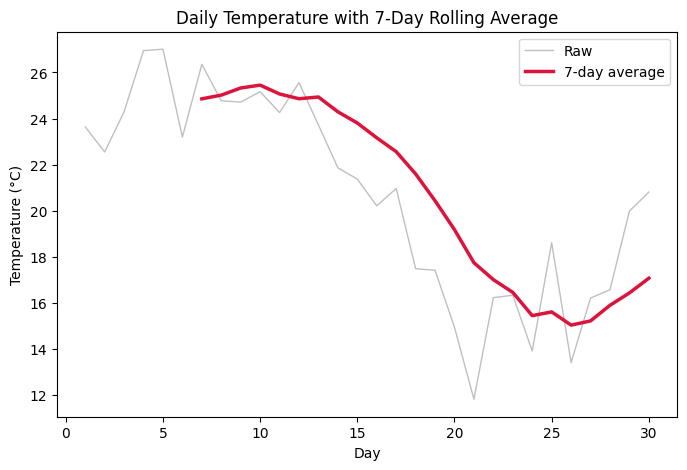

In [ ]:
np.random.seed(0)
days = np.arange(1, 31)
temps = 20 + 5 * np.sin(days / 5) + np.random.normal(0, 1.5, size=30)

temps_series = pd.Series(temps)
rolling_avg = temps_series.rolling(7).mean()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(days, temps, color="gray", alpha=0.5, linewidth=1, label="Raw")
ax.plot(days, rolling_avg, color="crimson", linewidth=2.5, label="7-day average")

ax.set_title("Daily Temperature with 7-Day Rolling Average")
ax.set_xlabel("Day")
ax.set_ylabel("Temperature (°C)")
ax.legend()
plt.show()


### Quiz (Chapter 4)
1. When is a line plot the *wrong* chart choice, even for numeric data?
2. What does `alpha=0.5` do and when is it essential?
3. Name two ways (other than color) to visually distinguish overlapping lines.
4. What causes `ValueError: x and y must have the same first dimension` and how do you debug it?

### Chapter 4 Summary
- Line plots assume meaningful order along x — never use them for unordered categories.
- Style parameters (`color`, `linestyle`, `marker`, `alpha`) exist to make multiple series distinguishable and to control emphasis/density.
- Training/validation curves are the flagship ML use case for this chart type.


---
# CHAPTER 5 — LABELS AND TITLES

## 1. Concept
`ax.set_title()`, `ax.set_xlabel()`, `ax.set_ylabel()` attach `Text` Artists to an Axes. They are not cosmetic extras — an axis without units or a plot without a title is, professionally, an **incomplete deliverable**: the reader has to guess what they're looking at.

## 2. Why It Matters
In a business or stakeholder context, a chart is often viewed **without you present to narrate it**. If the axes aren't labeled with units (e.g., "Revenue ($M)" not just "Revenue"), the chart is ambiguous or actively misleading.

## 3–4. NumPy / Pandas Connection
Labels are pure presentation — they don't touch the underlying data — but good practice is to derive them dynamically from your DataFrame column names/units rather than hardcoding, so the code stays correct if the data changes:
```python
ax.set_ylabel(f"{column_name} ({units[column_name]})")
```

## 5. Industry Use Case
Every report, dashboard, or portfolio figure needs a clear title and axis labels — this is often literally checked in code review / MNC project quality bars.


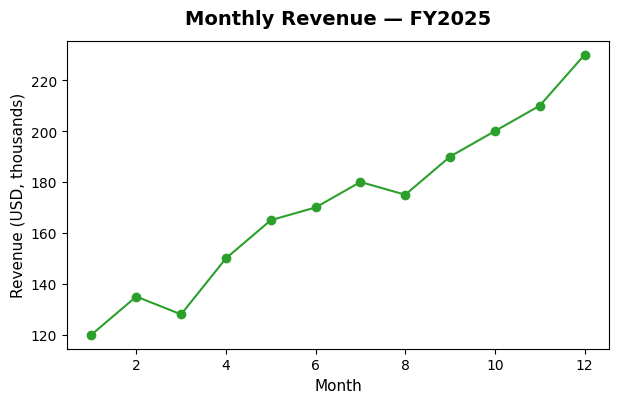

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))

x = np.arange(1, 13)
revenue = np.array([120, 135, 128, 150, 165, 170, 180, 175, 190, 200, 210, 230])

ax.plot(x, revenue, marker="o", color="#2ca02c")

ax.set_title(
    "Monthly Revenue — FY2025",
    fontsize=14,
    fontweight="bold",
    pad=12,          # extra space between title and plot
)
ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Revenue (USD, thousands)", fontsize=11)

plt.show()


### Parameter Explanation
| Parameter | Applies to | Meaning |
|---|---|---|
| `fontsize` | title/labels | Text size in points |
| `fontweight` | title/labels | `'normal'`, `'bold'`, or a numeric weight |
| `color` | title/labels | Text color |
| `pad` | `set_title` | Gap (in points) between title and the top of the Axes |
| `labelpad` | `set_xlabel`/`set_ylabel` | Gap between axis label and tick labels |
| `loc` | `set_title` | `'left'`, `'center'`, `'right'` alignment |

### Internal Working
`ax.set_title(...)` creates or updates a single `Text` Artist stored at `ax.title`; `set_xlabel`/`set_ylabel` similarly update `ax.xaxis.label` / `ax.yaxis.label`. Because these are just `Text` Artists, every standard Matplotlib text property (`fontsize`, `color`, `rotation`, `fontstyle`) applies uniformly.

### Bad vs Professional Example


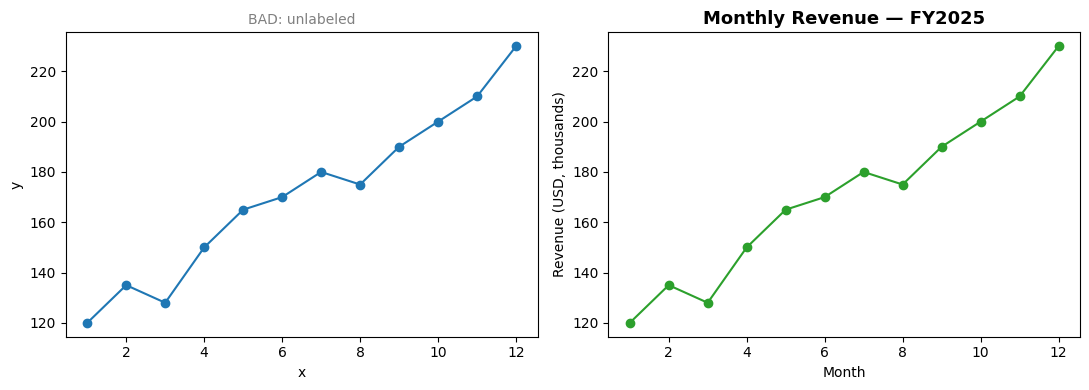

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# --- Bad: no title, no units, ambiguous label ---
axes[0].plot(x, revenue, marker="o")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")

# --- Professional: clear title, units, readable size ---
axes[1].plot(x, revenue, marker="o", color="#2ca02c")
axes[1].set_title("Monthly Revenue — FY2025", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Revenue (USD, thousands)")

axes[0].set_title("BAD: unlabeled", fontsize=10, color="gray")
plt.tight_layout()
plt.show()


### Interpretation
The left chart forces a viewer to guess whether "y" means dollars, units sold, or something else entirely — this ambiguity is a real, common defect in first-draft analyst notebooks.

### Common Mistakes
- Generic axis labels (`x`, `y`) left over from prototyping and never updated for the final deliverable.
- Missing units (a bare "Revenue" instead of "Revenue ($M)").
- Titles that describe the chart type instead of the insight (e.g., "Line Chart" instead of "Revenue Grew 92% YoY").

### Best Practices
- Always include units in the axis label when applicable.
- Keep titles concise but specific; for a stakeholder-facing report, an **insight-bearing title** ("Revenue accelerated in Q4") is often more effective than a purely descriptive one ("Monthly Revenue, FY2025") — know your audience and choose deliberately.
- Set a consistent `fontsize` scheme across a report (e.g., title=14, labels=11, ticks=9) — formalized project-wide via `rcParams` in Chapter 8.

### Interview Insight
**Q: Why does axis labeling matter for a "technically correct" chart?**
A: Correctness of the plotted data doesn't guarantee correctness of interpretation. Missing units or vague labels force the reader to guess context, which can lead to wrong business conclusions even when the underlying numbers are accurate — this is why label completeness is treated as a hard requirement in professional visualization review.

### Mini Exercise
Take the revenue plot and change the title's `loc` to `'left'`. Increase `labelpad` on the y-axis label to `15` and observe the spacing change.

### Coding Challenge
Write a function `label_axes(ax, title, xlabel, ylabel, title_size=14, label_size=11)` that applies a consistent labeling scheme to any Axes object in one call — this is the first building block of the reusable `visualization.py` module you'll build in Chapter 87.


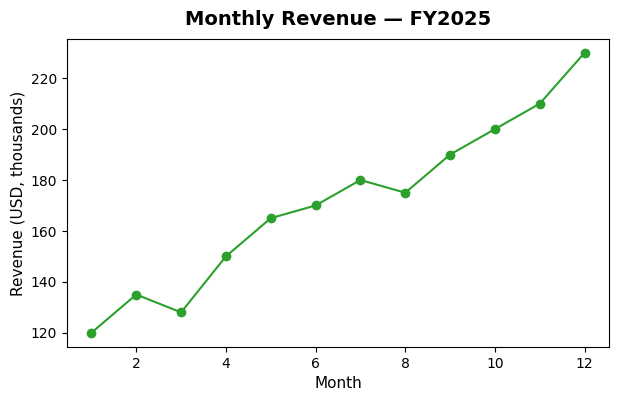

In [ ]:
def label_axes(ax, title, xlabel, ylabel, title_size=14, label_size=11):
    ax.set_title(title, fontsize=title_size, fontweight="bold", pad=10)
    ax.set_xlabel(xlabel, fontsize=label_size)
    ax.set_ylabel(ylabel, fontsize=label_size)
    return ax

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, revenue, marker="o", color="#2ca02c")
label_axes(ax, "Monthly Revenue — FY2025", "Month", "Revenue (USD, thousands)")
plt.show()


### Quiz (Chapter 5)
1. Where does `ax.set_title()` actually store its text internally?
2. Give two reasons a "technically correct" chart can still mislead a viewer.
3. What's the difference between `pad` (on `set_title`) and `labelpad` (on `set_xlabel`)?

### Chapter 5 Summary
- Titles and axis labels are `Text` Artists, fully stylable, and a **non-optional** part of a professional chart.
- Always include units; prefer specific, insight-bearing titles for stakeholder-facing work.
- `label_axes()`-style helper functions are the seed of a reusable visualization module (Chapter 87).

---

## END OF NOTEBOOK 1 — What You Should Now Be Able To Do
- Explain Figure vs Axes vs Axis correctly, without hesitation, in an interview.
- Default to `fig, ax = plt.subplots()` instead of bare `plt.plot()`.
- Build a fully-labeled, styled line plot from NumPy/Pandas data and explain every parameter you used.
- Recognize why an unlabeled chart is an incomplete deliverable.

## Before Moving to Notebook 2 (Chapters 6–10: Legends, Colors, Styles/rcParams, Markers/Linestyles, Axis Limits)
Complete all Mini Exercises and Coding Challenges above.